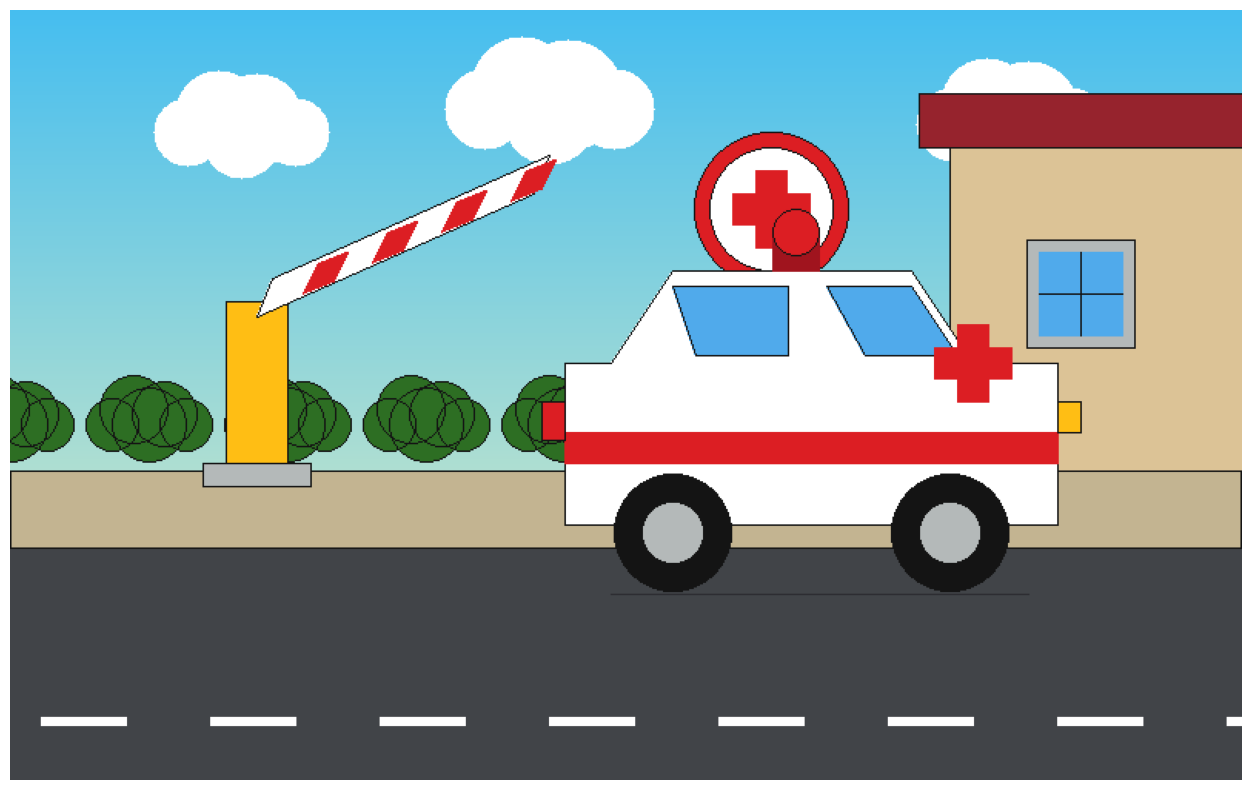

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import cos, sin, radians


# ============================================================
# 1. CANVAS SETTINGS
# ============================================================

WIDTH = 800
HEIGHT = 500

canvas = np.zeros((HEIGHT, WIDTH, 3), dtype=np.uint8)


# ============================================================
# 2. COLORS
# ============================================================

WHITE = np.array([255, 255, 255], dtype=np.uint8)
BLACK = np.array([20, 20, 20], dtype=np.uint8)

RED = np.array([220, 30, 35], dtype=np.uint8)
DARK_RED = np.array([160, 20, 30], dtype=np.uint8)

BLUE = np.array([80, 170, 235], dtype=np.uint8)
LIGHT_BLUE = np.array([170, 225, 255], dtype=np.uint8)

GREEN = np.array([75, 150, 55], dtype=np.uint8)
DARK_GREEN = np.array([45, 110, 35], dtype=np.uint8)

GRAY = np.array([90, 90, 90], dtype=np.uint8)
DARK_GRAY = np.array([45, 45, 50], dtype=np.uint8)
LIGHT_GRAY = np.array([180, 185, 185], dtype=np.uint8)

YELLOW = np.array([255, 190, 20], dtype=np.uint8)
ORANGE = np.array([245, 150, 10], dtype=np.uint8)

BUILDING = np.array([220, 195, 150], dtype=np.uint8)
ROOF = np.array([150, 35, 45], dtype=np.uint8)

SKY_TOP = np.array([70, 190, 240], dtype=np.uint8)
SKY_BOTTOM = np.array([245, 245, 190], dtype=np.uint8)

ROAD = np.array([65, 68, 72], dtype=np.uint8)
SIDEWALK = np.array([195, 180, 145], dtype=np.uint8)


# ============================================================
# 3. BASIC PIXEL FUNCTION
# ============================================================

def put_pixel(x, y, color):

    if 0 <= x < WIDTH and 0 <= y < HEIGHT:

        # Convert Cartesian coordinates
        # to NumPy image coordinates
        canvas[HEIGHT - 1 - y, x] = color


# ============================================================
# 4. BRESENHAM LINE ALGORITHM
# ============================================================

def bresenham(x1, y1, x2, y2, color):

    dx = abs(x2 - x1)
    dy = abs(y2 - y1)

    sx = 1 if x2 > x1 else -1
    sy = 1 if y2 > y1 else -1

    err = dx - dy

    while True:

        put_pixel(x1, y1, color)

        if x1 == x2 and y1 == y2:
            break

        e2 = 2 * err

        if e2 > -dy:

            err -= dy
            x1 += sx

        if e2 < dx:

            err += dx
            y1 += sy


# ============================================================
# 5. MIDPOINT CIRCLE ALGORITHM
# ============================================================

def plot_circle_points(xc, yc, x, y, color):

    points = [

        (xc + x, yc + y),
        (xc - x, yc + y),

        (xc + x, yc - y),
        (xc - x, yc - y),

        (xc + y, yc + x),
        (xc - y, yc + x),

        (xc + y, yc - x),
        (xc - y, yc - x)

    ]

    for px, py in points:

        put_pixel(px, py, color)


def midpoint_circle(xc, yc, r, color):

    x = 0
    y = r

    p = 1 - r

    while x <= y:

        plot_circle_points(
            xc,
            yc,
            x,
            y,
            color
        )

        x += 1

        if p < 0:

            p += 2 * x + 1

        else:

            y -= 1

            p += 2 * (x - y) + 1


# ============================================================
# 6. FILLED CIRCLE
# ============================================================

def fill_circle(xc, yc, r, color):

    for y in range(yc - r, yc + r + 1):

        for x in range(xc - r, xc + r + 1):

            if (x - xc) ** 2 + (y - yc) ** 2 <= r ** 2:

                put_pixel(x, y, color)


# ============================================================
# 7. RECTANGLE
# ============================================================

def draw_rectangle(x1, y1, x2, y2, color):

    bresenham(x1, y1, x2, y1, color)
    bresenham(x2, y1, x2, y2, color)
    bresenham(x2, y2, x1, y2, color)
    bresenham(x1, y2, x1, y1, color)


def fill_rectangle(x1, y1, x2, y2, color):

    for y in range(y1, y2 + 1):

        bresenham(
            x1,
            y,
            x2,
            y,
            color
        )


# ============================================================
# 8. FILLED POLYGON
# ============================================================

def fill_polygon(points, color):

    min_y = max(0, min(y for x, y in points))
    max_y = min(HEIGHT - 1, max(y for x, y in points))

    for y in range(min_y, max_y + 1):

        intersections = []

        for i in range(len(points)):

            x1, y1 = points[i]

            x2, y2 = points[(i + 1) % len(points)]

            if y1 == y2:
                continue

            if min(y1, y2) <= y < max(y1, y2):

                x = x1 + (y - y1) * (x2 - x1) / (y2 - y1)

                intersections.append(int(x))

        intersections.sort()

        for i in range(0, len(intersections) - 1, 2):

            x_start = intersections[i]
            x_end = intersections[i + 1]

            for x in range(x_start, x_end + 1):

                put_pixel(x, y, color)


def draw_polygon(points, color):

    for i in range(len(points)):

        x1, y1 = points[i]

        x2, y2 = points[(i + 1) % len(points)]

        bresenham(
            x1,
            y1,
            x2,
            y2,
            color
        )


# ============================================================
# 9. TRANSLATION
# ============================================================

def translate(points, tx, ty):

    return [

        (x + tx, y + ty)

        for x, y in points

    ]


# ============================================================
# 10. ROTATION
# ============================================================

def rotate(points, pivot, angle):

    px, py = pivot

    a = radians(angle)

    result = []

    for x, y in points:

        x -= px
        y -= py

        xr = x * cos(a) - y * sin(a)

        yr = x * sin(a) + y * cos(a)

        result.append(

            (
                round(xr + px),
                round(yr + py)
            )

        )

    return result


# ============================================================
# 11. COHEN-SUTHERLAND CLIPPING
# ============================================================

XMIN = 0
XMAX = WIDTH - 1
YMIN = 0
YMAX = HEIGHT - 1

INSIDE = 0
LEFT = 1
RIGHT = 2
BOTTOM = 4
TOP = 8


def compute_code(x, y):

    code = INSIDE

    if x < XMIN:
        code |= LEFT

    elif x > XMAX:
        code |= RIGHT

    if y < YMIN:
        code |= BOTTOM

    elif y > YMAX:
        code |= TOP

    return code


def cohen_sutherland(x1, y1, x2, y2, color):

    code1 = compute_code(x1, y1)

    code2 = compute_code(x2, y2)

    while True:

        if code1 == 0 and code2 == 0:

            bresenham(
                int(x1),
                int(y1),
                int(x2),
                int(y2),
                color
            )

            break

        elif code1 & code2:

            break

        else:

            code_out = code1 if code1 else code2

            if code_out & TOP:

                if y2 == y1:
                    break

                x = x1 + (x2 - x1) * \
                    (YMAX - y1) / (y2 - y1)

                y = YMAX

            elif code_out & BOTTOM:

                if y2 == y1:
                    break

                x = x1 + (x2 - x1) * \
                    (YMIN - y1) / (y2 - y1)

                y = YMIN

            elif code_out & RIGHT:

                if x2 == x1:
                    break

                y = y1 + (y2 - y1) * \
                    (XMAX - x1) / (x2 - x1)

                x = XMAX

            else:

                if x2 == x1:
                    break

                y = y1 + (y2 - y1) * \
                    (XMIN - x1) / (x2 - x1)

                x = XMIN

            if code_out == code1:

                x1 = int(x)
                y1 = int(y)

                code1 = compute_code(x1, y1)

            else:

                x2 = int(x)
                y2 = int(y)

                code2 = compute_code(x2, y2)


# ============================================================
# 12. BACKGROUND SKY GRADIENT
# ============================================================

for y in range(HEIGHT):

    t = y / (HEIGHT - 1)

    color = (

        SKY_BOTTOM * (1 - t)

        +

        SKY_TOP * t

    ).astype(np.uint8)

    for x in range(WIDTH):

        put_pixel(
            x,
            y,
            color
        )


# ============================================================
# 13. CLOUD FUNCTION
# ============================================================

def draw_cloud(x, y, scale=1):

    circles = [

        (-35, 0, 22),
        (-15, 12, 28),
        (10, 8, 30),
        (35, 0, 22),
        (0, -5, 25)

    ]

    for dx, dy, r in circles:

        fill_circle(

            x + int(dx * scale),

            y + int(dy * scale),

            int(r * scale),

            WHITE

        )


# Clouds

draw_cloud(150, 420, 1.0)

draw_cloud(350, 435, 1.2)

draw_cloud(650, 425, 1.1)


# ============================================================
# 14. TREES / BUSHES
# ============================================================

def draw_bush(x, y, scale=1):

    circles = [

        (-35, 0, 25),
        (-15, 15, 32),
        (15, 10, 30),
        (35, 0, 25),
        (0, 0, 35)

    ]

    for dx, dy, r in circles:

        fill_circle(

            x + int(dx * scale),

            y + int(dy * scale),

            int(r * scale),

            DARK_GREEN

        )

    for dx, dy, r in circles:

        midpoint_circle(

            x + int(dx * scale),

            y + int(dy * scale),

            int(r * scale),

            BLACK

        )


# Bush line

for x in range(0, WIDTH, 90):

    draw_bush(
        x,
        230,
        0.7
    )


# ============================================================
# 15. SIDEWALK
# ============================================================

fill_rectangle(
    0,
    150,
    WIDTH - 1,
    200,
    SIDEWALK
)

draw_rectangle(
    0,
    150,
    WIDTH - 1,
    200,
    BLACK
)


# ============================================================
# 16. ROAD
# ============================================================

fill_rectangle(
    0,
    0,
    WIDTH - 1,
    150,
    ROAD
)


# Road top boundary

bresenham(
    0,
    150,
    WIDTH - 1,
    150,
    BLACK
)


# ============================================================
# 17. ROAD LANE MARKINGS
# ============================================================

for x in range(20, WIDTH, 110):

    fill_rectangle(

        x,
        35,
        x + 55,
        40,

        WHITE

    )


# ============================================================
# 18. BUILDING
# ============================================================

building = [

    (610, 200),
    (800, 200),
    (800, 410),
    (610, 410)

]

fill_polygon(
    building,
    BUILDING
)

draw_polygon(
    building,
    BLACK
)


# Roof

roof = [

    (590, 410),
    (800, 410),
    (800, 445),
    (590, 445)

]

fill_polygon(
    roof,
    ROOF
)

draw_polygon(
    roof,
    BLACK
)


# ============================================================
# 19. BUILDING WINDOW
# ============================================================

fill_rectangle(
    660,
    280,
    730,
    350,
    LIGHT_GRAY
)

draw_rectangle(
    660,
    280,
    730,
    350,
    BLACK
)


fill_rectangle(
    668,
    288,
    722,
    342,
    BLUE
)

# Vertical window line

bresenham(
    695,
    288,
    695,
    342,
    BLACK
)

# Horizontal window line

bresenham(
    668,
    315,
    722,
    315,
    BLACK
)


# ============================================================
# 20. BARRIER GATE
# ============================================================

# Barrier stand

fill_rectangle(
    140,
    200,
    180,
    310,
    YELLOW
)

draw_rectangle(
    140,
    200,
    180,
    310,
    BLACK
)


# Barrier arm

barrier = [

    (160, 300),
    (340, 380),
    (350, 405),
    (170, 325)

]

# Rotate barrier slightly

barrier = rotate(
    barrier,
    (160, 300),
    0
)

fill_polygon(
    barrier,
    WHITE
)

draw_polygon(
    barrier,
    BLACK
)


# Red stripes on barrier

stripe_positions = [

    (190, 315),
    (235, 335),
    (280, 355),
    (325, 375)

]

for sx, sy in stripe_positions:

    stripe = [

        (sx, sy),
        (sx + 20, sy + 8),
        (sx + 30, sy + 28),
        (sx + 10, sy + 20)

    ]

    fill_polygon(
        stripe,
        RED
    )


# Barrier base

fill_rectangle(
    125,
    190,
    195,
    205,
    LIGHT_GRAY
)

draw_rectangle(
    125,
    190,
    195,
    205,
    BLACK
)


# ============================================================
# 21. MEDICAL SIGN
# ============================================================

# Sign pole

fill_rectangle(
    490,
    200,
    498,
    330,
    LIGHT_GRAY
)

draw_rectangle(
    490,
    200,
    498,
    330,
    BLACK
)


# Outer circle

fill_circle(
    494,
    370,
    50,
    RED
)

midpoint_circle(
    494,
    370,
    50,
    BLACK
)


# Inner white circle

fill_circle(
    494,
    370,
    40,
    WHITE
)

midpoint_circle(
    494,
    370,
    40,
    BLACK
)


# Red medical cross

fill_rectangle(
    484,
    345,
    504,
    395,
    RED
)

fill_rectangle(
    469,
    360,
    519,
    380,
    RED
)


# ============================================================
# 22. AMBULANCE BODY
# ============================================================

ambulance_body = [

    (360, 165),
    (680, 165),
    (680, 270),
    (625, 270),
    (585, 330),
    (430, 330),
    (390, 270),
    (360, 270)

]

fill_polygon(
    ambulance_body,
    WHITE
)

draw_polygon(
    ambulance_body,
    BLACK
)


# ============================================================
# 23. AMBULANCE RED STRIPE
# ============================================================

fill_rectangle(
    360,
    205,
    680,
    225,
    RED
)


# ============================================================
# 24. AMBULANCE WINDOWS
# ============================================================

front_window = [

    (555, 275),
    (615, 275),
    (585, 320),
    (530, 320)

]

fill_polygon(
    front_window,
    BLUE
)

draw_polygon(
    front_window,
    BLACK
)


rear_window = [

    (445, 275),
    (505, 275),
    (505, 320),
    (430, 320)

]

fill_polygon(
    rear_window,
    BLUE
)

draw_polygon(
    rear_window,
    BLACK
)


# ============================================================
# 25. AMBULANCE MEDICAL CROSS
# ============================================================

fill_rectangle(
    615,
    245,
    635,
    295,
    RED
)

fill_rectangle(
    600,
    260,
    650,
    280,
    RED
)


# ============================================================
# 26. AMBULANCE ROOF LIGHT
# ============================================================

fill_rectangle(
    495,
    330,
    525,
    355,
    DARK_RED
)

fill_circle(
    510,
    355,
    15,
    RED
)

midpoint_circle(
    510,
    355,
    15,
    BLACK
)


# ============================================================
# 27. WHEELS
# ============================================================

wheel_centers = [

    (430, 160),
    (610, 160)

]

for wx, wy in wheel_centers:

    fill_circle(
        wx,
        wy,
        38,
        BLACK
    )

    midpoint_circle(
        wx,
        wy,
        38,
        BLACK
    )

    fill_circle(
        wx,
        wy,
        20,
        LIGHT_GRAY
    )

    midpoint_circle(
        wx,
        wy,
        20,
        BLACK
    )


# ============================================================
# 28. HEADLIGHT
# ============================================================

fill_rectangle(
    680,
    225,
    695,
    245,
    YELLOW
)

draw_rectangle(
    680,
    225,
    695,
    245,
    BLACK
)


# ============================================================
# 29. REAR LIGHT
# ============================================================

fill_rectangle(
    345,
    220,
    360,
    245,
    RED
)

draw_rectangle(
    345,
    220,
    360,
    245,
    BLACK
)


# ============================================================
# 30. AMBULANCE SHADOW
# ============================================================

for x in range(390, 660):

    bresenham(
        x,
        120,
        x + 2,
        120,
        DARK_GRAY
    )


# ============================================================
# 31. DISPLAY RESULT
# ============================================================

plt.figure(
    figsize=(14, 8)
)

plt.imshow(canvas)

plt.axis("off")

plt.tight_layout()

plt.show()